#Dataset Link

https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

#Prompt for data loading and generating a data dictionary



given the dataset here as you can see it has data scattered across multiple sheets what i want is first combine this data into a single csv file and then based on the columns create a perfectly formatted data dictionary that can be copy pasted into colab text cell directly and give me the csv file

#Data Dictionary


# Data Dictionary – Electrical Output Prediction Dataset

| Column Name | Data Type | Description |
|---|---|---|
| AT | Float | Ambient Temperature measured in degrees Celsius (°C). Represents the surrounding environmental temperature affecting the power plant performance. |
| V | Float | Exhaust Vacuum measured in cm Hg. Indicates the vacuum level in the turbine condenser system. |
| AP | Float | Ambient Pressure measured in millibar (mbar). Represents atmospheric pressure conditions during power generation. |
| RH | Float | Relative Humidity measured as a percentage (%). Indicates the moisture content present in the surrounding air. |
| PE | Float | Electrical Energy Output measured in megawatts (MW). This is the target variable representing the net hourly electrical energy output of the power plant. |

## Dataset Summary

- Source File: electrical_op_prediction.xlsx
- Number of Sheets Combined: 5
- Total Rows After Combination: 47840
- Total Columns: 5
- Recommended Target Variable: `PE`
- Recommended Problem Type: Regression

## Suggested Use Cases

- Power plant energy output prediction
- Regression model development
- Feature importance analysis
- Environmental impact analysis on energy generation
- Machine learning benchmarking tasks


In [1]:
path = '/content/combined_electrical_op_prediction.csv'

# Core
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')


# Warnings
import warnings
warnings.filterwarnings('ignore')

# Statistics
from scipy.stats import pearsonr, spearmanr

# Train-test split
from sklearn.model_selection import train_test_split

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Deep Learning (Keras)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.layers import Dropout
# Evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv(path)
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [3]:
df.shape

(47840, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47840 entries, 0 to 47839
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      47840 non-null  float64
 1   V       47840 non-null  float64
 2   AP      47840 non-null  float64
 3   RH      47840 non-null  float64
 4   PE      47840 non-null  float64
dtypes: float64(5)
memory usage: 1.8 MB


In [5]:
df.describe()

,AT,V,AP,RH,PE
count,47840.000000,47840.000000,47840.000000,47840.000000,47840.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452162,12.707362,5.938535,14.599658,17.066281
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [6]:
df.dtypes

,0
AT,float64
V,float64
AP,float64
RH,float64
PE,float64


In [7]:
df.isna().sum()

,0
AT,0
V,0
AP,0
RH,0
PE,0


In [9]:
df.shape

(47840, 5)

In [8]:
df.duplicated().sum()

np.int64(38313)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.shape

(9527, 5)

#Analyze target variable behavior

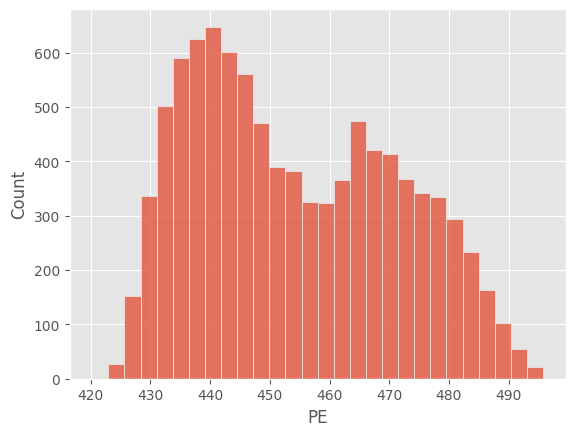

In [13]:
sns.histplot(df['PE'])
plt.show()

In [14]:
df['PE'].skew()

np.float64(0.3057905126118896)

#Outlier Detection and Treatment

In [15]:
df.columns

Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')

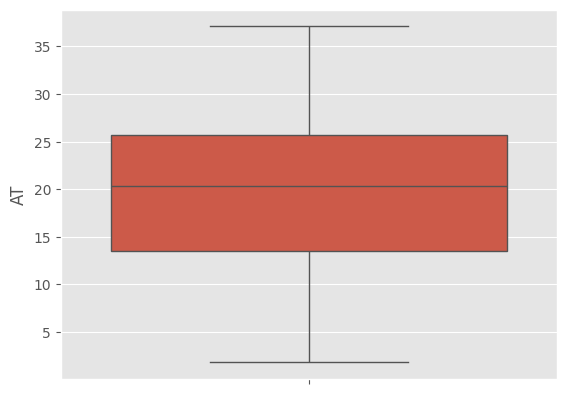

Outliers Found in column AT is 0


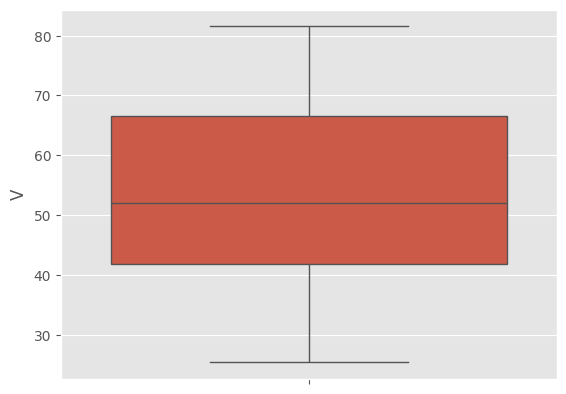

Outliers Found in column V is 0


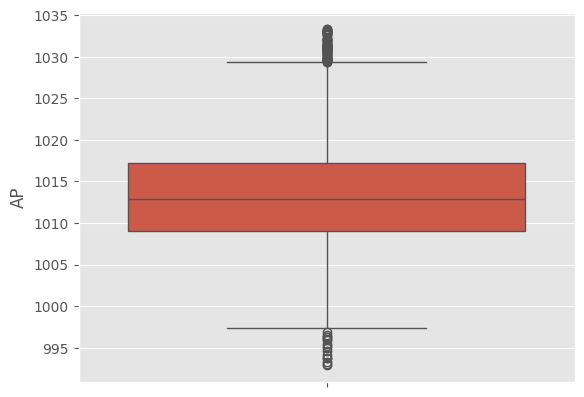

Outliers Found in column AP is 91


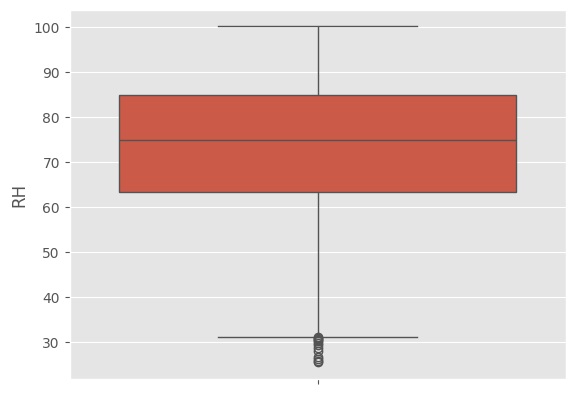

Outliers Found in column RH is 13


In [19]:
num_cols = ['AT', 'V', 'AP', 'RH']

idxs = []
for col in num_cols:
  q1 = np.percentile(df[col],25)
  q3 = np.percentile(df[col],75)
  iqr = q3-q1
  lb = q1-1.5*iqr
  ub = q3+1.5*iqr
  idx = df[(df[col]<lb) | (df[col]>ub)].index.tolist()
  sns.boxplot(df[col])
  plt.show()
  print(f'Outliers Found in column {col} is {len(idx)}')
  idxs.extend(idx)

In [20]:
idxs_to_be_removed = list(set(idxs))
print(f'Shape Before Dropping Outliers {df.shape}')
df.drop(idxs_to_be_removed,axis=0,inplace=True)
print(f'Shape After Dropping Outliers {df.shape}')

Shape Before Dropping Outliers (9527, 5)
Shape After Dropping Outliers (9423, 5)


#Exploratory Data Analysis (EDA)

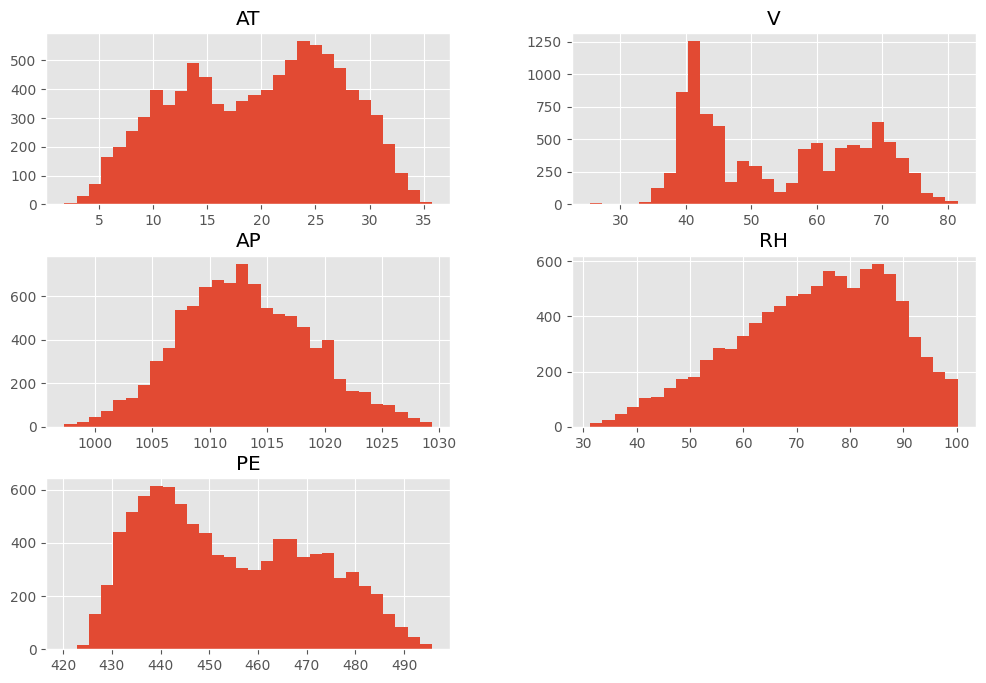

In [21]:
# Histogram plots
df.hist(figsize=(12,8), bins=30)
plt.show()


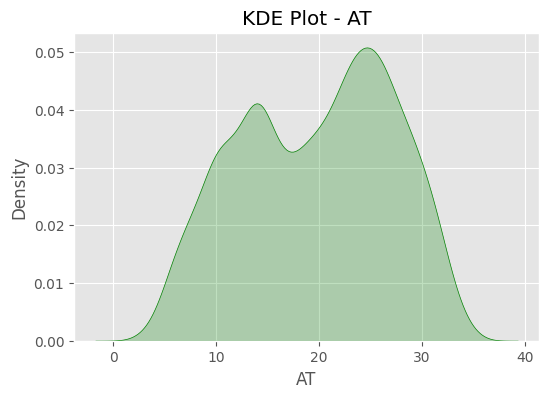

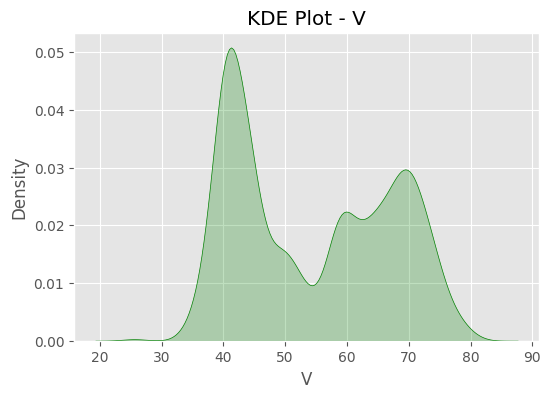

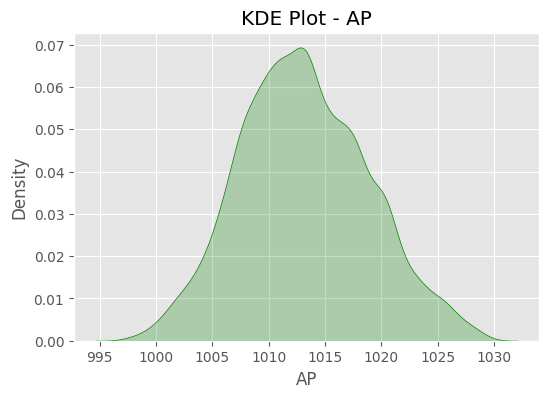

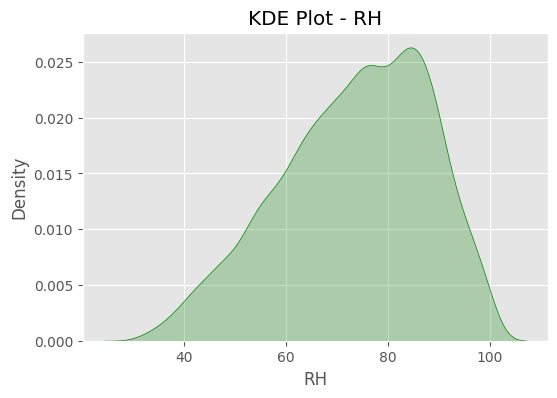

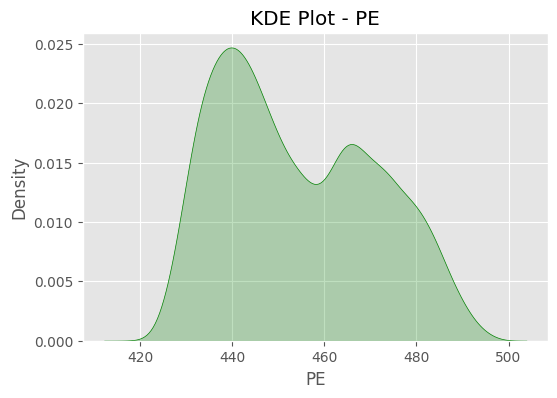

In [24]:
# KDE plots
for col in df.columns:
    plt.figure(figsize=(6,4))
    sns.kdeplot(df[col],fill=True,color='g')
    plt.title(f'KDE Plot - {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()


In [26]:
num_cols

['AT', 'V', 'AP', 'RH']

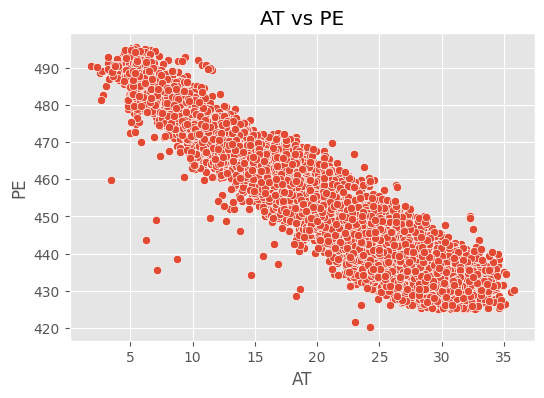

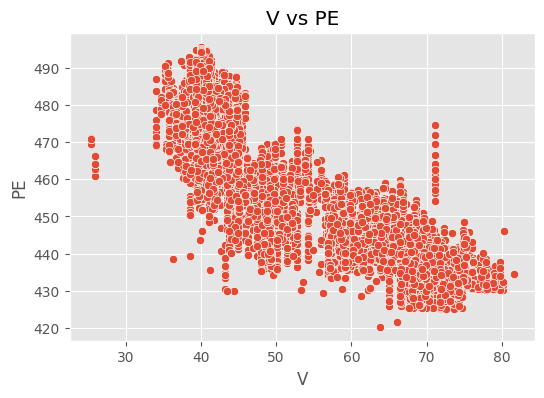

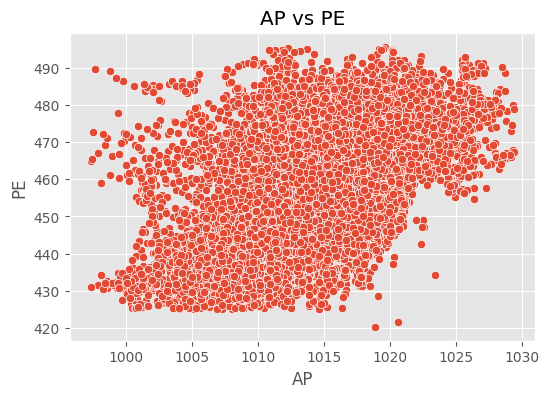

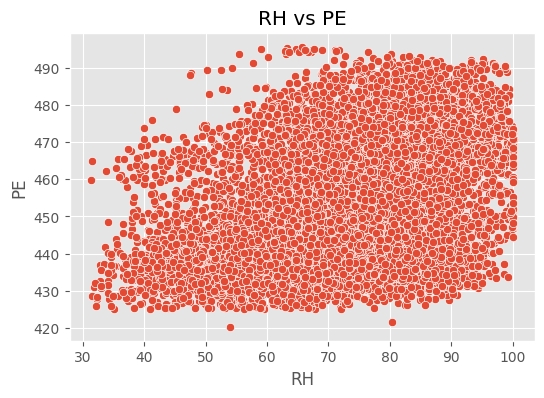

In [25]:
# =========================
# BIVARIATE ANALYSIS
# =========================

# Scatterplots with target variable


for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=df[col], y=df['PE'])
    plt.title(f'{col} vs PE')
    plt.xlabel(col)
    plt.ylabel('PE')
    plt.show()

## Relationship between environmental variables and energy production

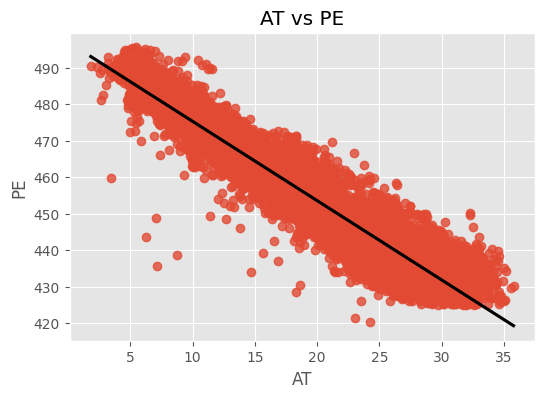

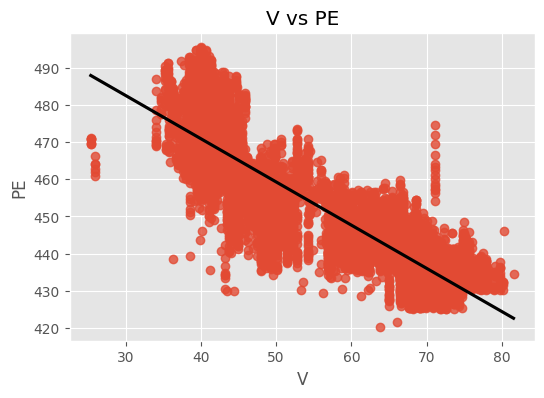

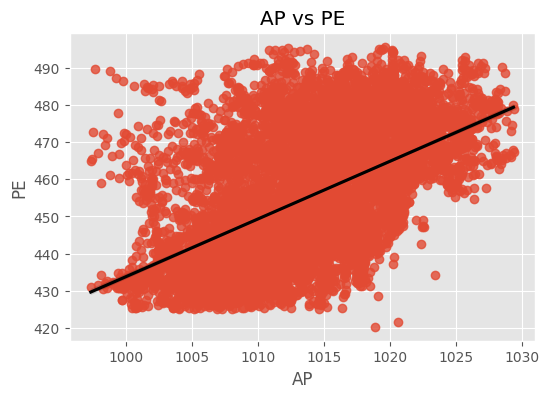

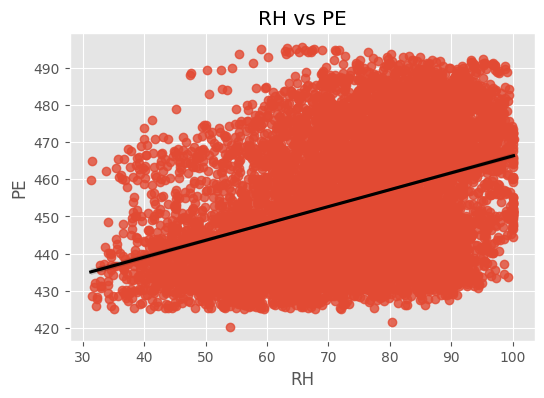

In [28]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.regplot(x=df[col], y=df['PE'],line_kws={'color':'k'})
    plt.title(f'{col} vs PE')
    plt.xlabel(col)
    plt.ylabel('PE')
    plt.show()

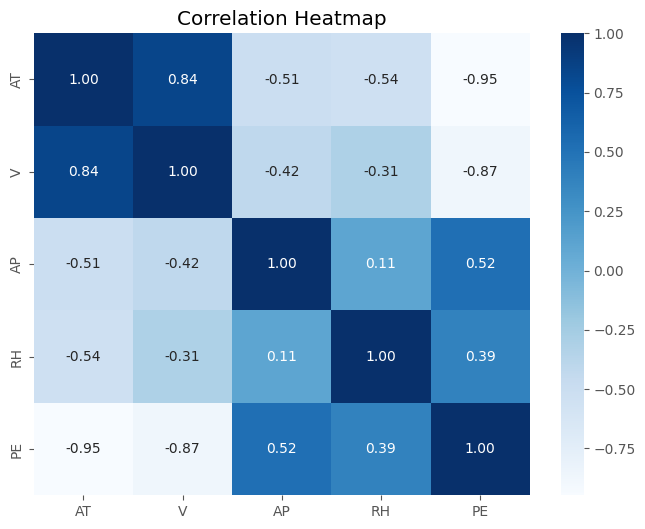

In [29]:
# Correlation Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(df.corr(),annot=True,cmap='Blues',fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()


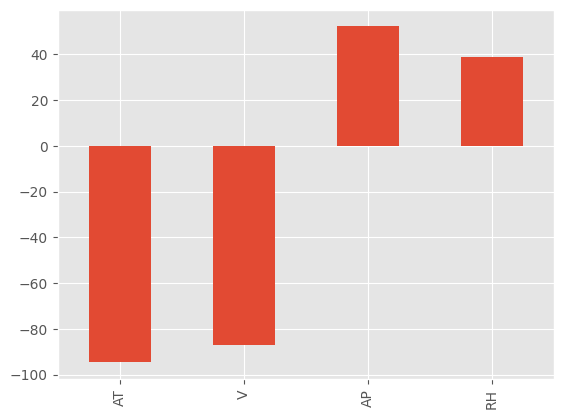

In [32]:
(df.corr()['PE'].drop(['PE'])*100).plot.bar()
plt.show()

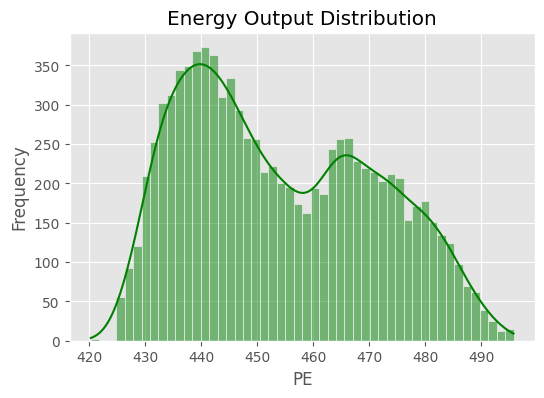

In [35]:
# =========================
# TARGET VARIABLE ANALYSIS
# =========================

# Energy Output Distribution
plt.figure(figsize=(6,4))
sns.histplot(df['PE'], kde=True, bins=50,color='g')

plt.title('Energy Output Distribution')
plt.xlabel('PE')
plt.ylabel('Frequency')
plt.show()

#Statistical Analysis

In [36]:
#H0:no impact
#H1:impact is significant

for col in num_cols:
  corr,p = pearsonr(df[col],df['PE'])
  print(f'Correlation Value {corr*100} %')
  print(f'P Value {p}')
  if p<0.05:
    print(f'Reject H0 and hence accept H1:{col} has a significant impact on the PE(target)')
  else:
    print(f'Reject H1 and hence accept H0:{col} has no impact on the PE(target)')


Correlation Value -94.72961223384016 %
P Value 0.0
Reject H0 and hence accept H1:AT has a significant impact on the PE(target)
Correlation Value -86.8846158067649 %
P Value 0.0
Reject H0 and hence accept H1:V has a significant impact on the PE(target)
Correlation Value 52.16500598838367 %
P Value 0.0
Reject H0 and hence accept H1:AP has a significant impact on the PE(target)
Correlation Value 38.943064777039325 %
P Value 0.0
Reject H0 and hence accept H1:RH has a significant impact on the PE(target)


In [37]:
for col in num_cols:
  corr,p = spearmanr(df[col],df['PE'])
  print(f'Correlation Value {corr*100} %')
  print(f'P Value {p}')
  if p<0.05:
    print(f'Reject H0 and hence accept H1:{col} has a significant impact on the PE(target)')
  else:
    print(f'Reject H1 and hence accept H0:{col} has no impact on the PE(target)')


Correlation Value -94.32014192677381 %
P Value 0.0
Reject H0 and hence accept H1:AT has a significant impact on the PE(target)
Correlation Value -88.36223961182498 %
P Value 0.0
Reject H0 and hence accept H1:V has a significant impact on the PE(target)
Correlation Value 54.18382797094712 %
P Value 0.0
Reject H0 and hence accept H1:AP has a significant impact on the PE(target)
Correlation Value 38.98808005542226 %
P Value 0.0
Reject H0 and hence accept H1:RH has a significant impact on the PE(target)


#Check for Normality

In [39]:
#use shapiro wilk test
from scipy.stats import shapiro

# Null Hypothesis (H0):
# The data follows a normal distribution.

# Alternative Hypothesis (H1):
# The data does not follow a normal distribution.

shapiro(df['AT'])

ShapiroResult(statistic=np.float64(0.9710430701301156), pvalue=np.float64(8.609655334343252e-40))

In [41]:
p =shapiro(df['AT'])[1]
p

# as p < 0.05 hence we conculde that the column AT does not follow a normal distribution.

np.float64(8.609655334343252e-40)

In [42]:
for col in num_cols:
  p = shapiro(df[col])[1]
  print(f'P Value {p}')
  if p<0.05:
    print(f'Reject H0 and hence accept H1:{col} does not follow a normal distribution.')
  else:
    print(f'Reject H1 and hence accept H0:{col} does follow a normal distribution.')

P Value 8.609655334343252e-40
Reject H0 and hence accept H1:AT does not follow a normal distribution.
P Value 1.774226053504894e-59
Reject H0 and hence accept H1:V does not follow a normal distribution.
P Value 5.769895676253455e-16
Reject H0 and hence accept H1:AP does not follow a normal distribution.
P Value 3.3286255595881186e-36
Reject H0 and hence accept H1:RH does not follow a normal distribution.


In [43]:
df[num_cols].skew()

,0
AT,-0.153466
V,0.180896
AP,0.174916
RH,-0.413956


In [44]:
df[num_cols].kurtosis()

,0
AT,-1.022691
V,-1.445057
AP,-0.285961
RH,-0.503436


In [45]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

df[num_cols] = pt.fit_transform(df[num_cols])

In [46]:
df[num_cols].skew()

,0
AT,-0.153926
V,-0.001215
AP,0.000000
RH,-0.106124


In [47]:
df[num_cols].kurtosis()

,0
AT,-1.022445
V,-1.438549
AP,0.000000
RH,-0.771884


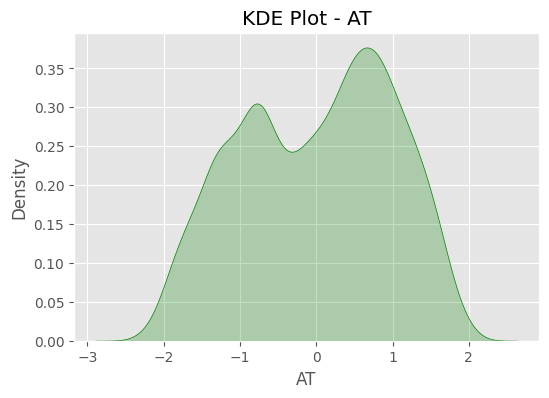

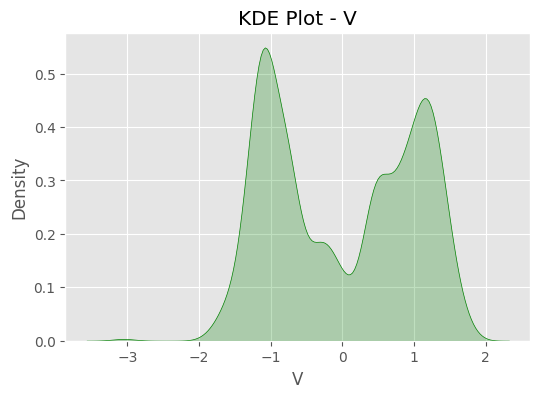

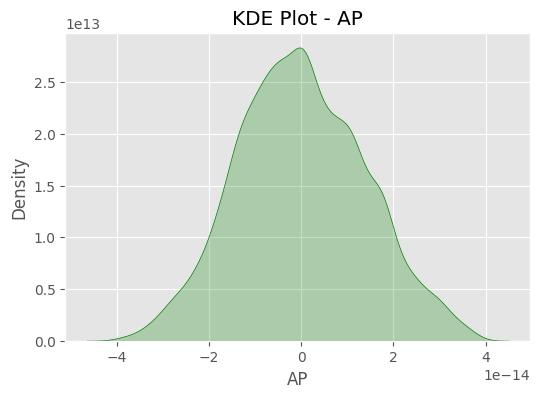

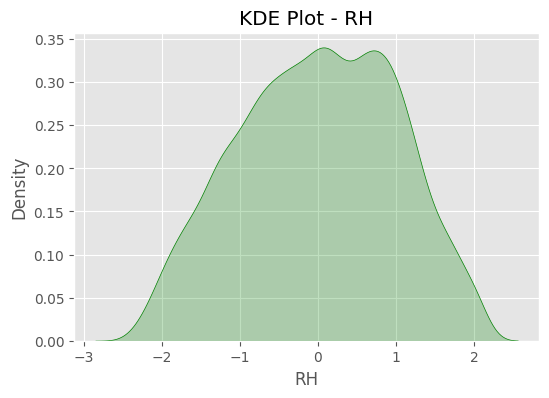

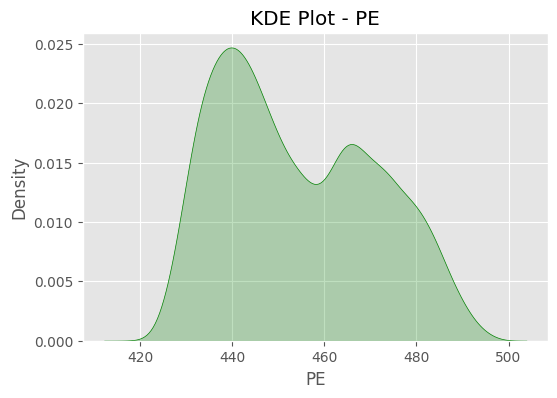

In [48]:
#after applying PT lets see how did it transform the data shape

for col in df.columns:
    plt.figure(figsize=(6,4))
    sns.kdeplot(df[col],fill=True,color='g')
    plt.title(f'KDE Plot - {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()


#Feature Engineering

based on the given features in the dataset i need to create new features that will amplify the pattern recognition of the deep learning model and beware of data leakage
create 4 new features that will help create a more robust model

In [49]:
# ==========================================
# FEATURE ENGINEERING
# ==========================================

# 1. Temperature-Humidity Interaction
# Captures combined environmental thermal effect
df['AT_RH_Interaction'] = df['AT'] * df['RH']


# 2. Vacuum-Pressure Difference
# Helps model atmospheric pressure imbalance effects
df['V_AP_Diff'] = df['V'] - df['AP']


# 3. Thermal Efficiency Index
# Captures efficiency relationship between temperature and vacuum
df['Thermal_Efficiency_Index'] = df['AT'] / (df['V'] + 1)


# 4. Combined Environmental Stress
# Aggregates major environmental stress contributors
df['Environmental_Stress'] = (
    df['AT'] + df['RH'] + df['V']
) / 3

In [50]:
df.head()

,AT,V,AP,RH,PE,AT_RH_Interaction,V_AP_Diff,Thermal_Efficiency_Index,Environmental_Stress
0,-0.642906,-1.006567,2.631229e-14,-0.091594,463.26,0.058886,-1.006567,97.904791,-0.580356
1,0.735175,0.735702,1.687539e-14,-1.013749,444.37,-0.745283,0.735702,0.423561,0.152376
2,-1.971812,-1.251604,-2.164935e-15,1.381145,488.56,-2.723360,-1.251604,7.836968,-0.614090
3,0.152725,0.335589,-6.883383e-15,0.158314,446.48,0.024179,0.335589,0.114350,0.215543
4,-1.201334,-1.459396,-9.381385e-15,1.766353,473.90,-2.121980,-1.459396,2.615030,-0.298125


In [51]:
df.columns

Index(['AT', 'V', 'AP', 'RH', 'PE', 'AT_RH_Interaction', 'V_AP_Diff',
       'Thermal_Efficiency_Index', 'Environmental_Stress'],
      dtype='object')

In [53]:
df = df[['AT', 'V', 'AP', 'RH','AT_RH_Interaction', 'V_AP_Diff',
       'Thermal_Efficiency_Index', 'Environmental_Stress','PE']]

df.head()

,AT,V,AP,RH,AT_RH_Interaction,V_AP_Diff,Thermal_Efficiency_Index,Environmental_Stress,PE
0,-0.642906,-1.006567,2.631229e-14,-0.091594,0.058886,-1.006567,97.904791,-0.580356,463.26
1,0.735175,0.735702,1.687539e-14,-1.013749,-0.745283,0.735702,0.423561,0.152376,444.37
2,-1.971812,-1.251604,-2.164935e-15,1.381145,-2.723360,-1.251604,7.836968,-0.614090,488.56
3,0.152725,0.335589,-6.883383e-15,0.158314,0.024179,0.335589,0.114350,0.215543,446.48
4,-1.201334,-1.459396,-9.381385e-15,1.766353,-2.121980,-1.459396,2.615030,-0.298125,473.90
